<h1 align="center">Practice 4. APIs & Static Web Scraping: REST API requests, JSON extraction + 
BeautifulSoup static HTML parsing.</h1>

### Topic 

Books

### Imports

In [76]:
import re
import json
from time import sleep
import requests as req
from bs4 import BeautifulSoup
import pandas as pd
import seaborn as sns

## Task 1. Choose data sources 

### Selected data sources:

1. API: [Gutendex](https://gutendex.com/)
2. Static Webpage: [Books to Scrape](https://books.toscrape.com/index.html)

## Task 2. API data collection

In [6]:
API_BASE_URL = "https://gutendex.com/"

In [7]:
# list of books
response = req.get(url=f"{API_BASE_URL}books")
status = response.status_code
books_data = response.json()
print(f"{status=} {type(books_data)}")
print(f"keys: {books_data.keys()}")

status=200 <class 'dict'>
keys: dict_keys(['count', 'next', 'previous', 'results'])


In [8]:
# single book
books_data["results"][0].keys()

dict_keys(['id', 'title', 'authors', 'summaries', 'editors', 'translators', 'subjects', 'bookshelves', 'languages', 'copyright', 'media_type', 'formats', 'download_count'])

### Exctracting 1000 books

Each page contains 32 book records, 32 get requests needed

In [9]:
books_records_list = []
for page in range(1, 33):
    params = {
        "page": page,
        "sort": "ascending"
    }
    response = req.get(url=f"{API_BASE_URL}/books", params=params)
    print(f"{page=} status: {response.status_code}")
    data = response.json()
    books_records_list.extend(data["results"])
    sleep(0.1)
print(f"First record example title: {books_records_list[0]["title"]}")

page=1 status: 200
page=2 status: 200
page=3 status: 200
page=4 status: 200
page=5 status: 200
page=6 status: 200
page=7 status: 200
page=8 status: 200
page=9 status: 200
page=10 status: 200
page=11 status: 200
page=12 status: 200
page=13 status: 200
page=14 status: 200
page=15 status: 200
page=16 status: 200
page=17 status: 200
page=18 status: 200
page=19 status: 200
page=20 status: 200
page=21 status: 200
page=22 status: 200
page=23 status: 200
page=24 status: 200
page=25 status: 200
page=26 status: 200
page=27 status: 200
page=28 status: 200
page=29 status: 200
page=30 status: 200
page=31 status: 200
page=32 status: 200
First record example title: The Declaration of Independence of the United States of America


In [80]:
# pd.read_json(json.dumps(books_records_list)) file name too long

In [10]:
books_api_df = pd.DataFrame(
    books_records_list
)
books_api_df = books_api_df[["id", "title", "authors", "summaries", "languages", "copyright", "download_count"]]

## Task 3. JSON processing

In [11]:
books_api_df.head()

,id,title,authors,summaries,languages,copyright,download_count
0,1,The Declaration of Independence of the United ...,"[{'name': 'Jefferson, Thomas', 'birth_year': 1...","[""The Declaration of Independence of the Unite...",[en],False,8535
1,2,The United States Bill of Rights: The Ten Orig...,"[{'name': 'United States', 'birth_year': None,...","[""The United States Bill of Rights"" by United ...",[en],False,2745
2,3,John F. Kennedy's Inaugural Address,"[{'name': 'Kennedy, John F. (John Fitzgerald)'...","[""John F. Kennedy's Inaugural Address"" by John...",[en],False,1852
3,4,Lincoln's Gettysburg Address: Given November 1...,"[{'name': 'Lincoln, Abraham', 'birth_year': 18...","[""Lincoln's Gettysburg Address"" by Abraham Lin...",[en],False,2500
4,5,The United States Constitution,"[{'name': 'United States', 'birth_year': None,...","[""The United States Constitution"" by United St...",[en],False,3474


In [12]:
books_api_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1024 entries, 0 to 1023
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id              1024 non-null   int64 
 1   title           1024 non-null   str   
 2   authors         1024 non-null   object
 3   summaries       1024 non-null   object
 4   languages       1024 non-null   object
 5   copyright       1024 non-null   bool  
 6   download_count  1024 non-null   int64 
dtypes: bool(1), int64(2), object(3), str(1)
memory usage: 83.8+ KB


In [13]:
def parse_authors(authors: list[dict[str, str]]) -> str:
    if not authors: return pd.NA
    return "|".join(author["name"] for author in authors)
    
def parse_summaries(summaries: list[str]) -> str:
    if not summaries: return pd.NA
    return ",".join(summaries)

def parse_languages(languages: list[str]) -> str:
    if not languages: return pd.NA
    return ",".join(languages)

In [14]:
books_api_df["authors"] = books_api_df["authors"].apply(parse_authors).astype(str)
books_api_df["summaries"] = books_api_df["summaries"].apply(parse_summaries).astype(str)
books_api_df["languages"] = books_api_df["languages"].apply(parse_languages).astype(str)

In [15]:
books_api_df.head()

,id,title,authors,summaries,languages,copyright,download_count
0,1,The Declaration of Independence of the United ...,"Jefferson, Thomas","""The Declaration of Independence of the United...",en,False,8535
1,2,The United States Bill of Rights: The Ten Orig...,United States,"""The United States Bill of Rights"" by United S...",en,False,2745
2,3,John F. Kennedy's Inaugural Address,"Kennedy, John F. (John Fitzgerald)","""John F. Kennedy's Inaugural Address"" by John ...",en,False,1852
3,4,Lincoln's Gettysburg Address: Given November 1...,"Lincoln, Abraham","""Lincoln's Gettysburg Address"" by Abraham Linc...",en,False,2500
4,5,The United States Constitution,United States,"""The United States Constitution"" by United Sta...",en,False,3474


In [16]:
books_api_df.dtypes

id                int64
title               str
authors             str
summaries           str
languages           str
copyright          bool
download_count    int64
dtype: object

In [18]:
books_api_df.to_csv("./books_api_dataset.csv", index=False)

## Task 4. Web scraping

In [19]:
STATIC_WEBPAGE_URL = "https://books.toscrape.com"

In [20]:
response = req.get(url=STATIC_WEBPAGE_URL)
print(f"Status: {response.status_code}")
html_text = response.text

Status: 200


In [21]:
soup = BeautifulSoup(html_text)

In [22]:
book_details_links = []
for card in soup.body.find_all(class_="product_pod"):
    book_details_links.append(card.find(class_="thumbnail").parent.get("href"))

In [23]:
book_details_links

['catalogue/a-light-in-the-attic_1000/index.html',
 'catalogue/tipping-the-velvet_999/index.html',
 'catalogue/soumission_998/index.html',
 'catalogue/sharp-objects_997/index.html',
 'catalogue/sapiens-a-brief-history-of-humankind_996/index.html',
 'catalogue/the-requiem-red_995/index.html',
 'catalogue/the-dirty-little-secrets-of-getting-your-dream-job_994/index.html',
 'catalogue/the-coming-woman-a-novel-based-on-the-life-of-the-infamous-feminist-victoria-woodhull_993/index.html',
 'catalogue/the-boys-in-the-boat-nine-americans-and-their-epic-quest-for-gold-at-the-1936-berlin-olympics_992/index.html',
 'catalogue/the-black-maria_991/index.html',
 'catalogue/starving-hearts-triangular-trade-trilogy-1_990/index.html',
 'catalogue/shakespeares-sonnets_989/index.html',
 'catalogue/set-me-free_988/index.html',
 'catalogue/scott-pilgrims-precious-little-life-scott-pilgrim-1_987/index.html',
 'catalogue/rip-it-up-and-start-again_986/index.html',
 'catalogue/our-band-could-be-your-life-scene

In [24]:
scraping_books_records_list = []
for link in book_details_links:
    response = req.get(url=f"{STATIC_WEBPAGE_URL}/{link}")
    print(f"{link.split("/")[-2]} status: {response.status_code}")
    soup = BeautifulSoup(response.text)
    product_main_info = soup.find(class_="product_main")
    product_table_info = soup.find("table")
    scraping_books_records_list.append(
        {
            "title": product_main_info.h1.string,
            "price": product_main_info.h1.next_sibling.next_sibling.string,
            "status": product_main_info.find(class_="instock").contents[-1],
            "UPC": product_table_info.find("tr").td.string
        }
    )
    sleep(0.1)
scraping_books_records_list

a-light-in-the-attic_1000 status: 200
tipping-the-velvet_999 status: 200
soumission_998 status: 200
sharp-objects_997 status: 200
sapiens-a-brief-history-of-humankind_996 status: 200
the-requiem-red_995 status: 200
the-dirty-little-secrets-of-getting-your-dream-job_994 status: 200
the-coming-woman-a-novel-based-on-the-life-of-the-infamous-feminist-victoria-woodhull_993 status: 200
the-boys-in-the-boat-nine-americans-and-their-epic-quest-for-gold-at-the-1936-berlin-olympics_992 status: 200
the-black-maria_991 status: 200
starving-hearts-triangular-trade-trilogy-1_990 status: 200
shakespeares-sonnets_989 status: 200
set-me-free_988 status: 200
scott-pilgrims-precious-little-life-scott-pilgrim-1_987 status: 200
rip-it-up-and-start-again_986 status: 200
our-band-could-be-your-life-scenes-from-the-american-indie-underground-1981-1991_985 status: 200
olio_984 status: 200
mesaerion-the-best-science-fiction-stories-1800-1849_983 status: 200
libertarianism-for-beginners_982 status: 200
its-only

[{'title': 'A Light in the Attic',
  'price': 'Â£51.77',
  'status': '\n    \n        In stock (22 available)\n    \n',
  'UPC': 'a897fe39b1053632'},
 {'title': 'Tipping the Velvet',
  'price': 'Â£53.74',
  'status': '\n    \n        In stock (20 available)\n    \n',
  'UPC': '90fa61229261140a'},
 {'title': 'Soumission',
  'price': 'Â£50.10',
  'status': '\n    \n        In stock (20 available)\n    \n',
  'UPC': '6957f44c3847a760'},
 {'title': 'Sharp Objects',
  'price': 'Â£47.82',
  'status': '\n    \n        In stock (20 available)\n    \n',
  'UPC': 'e00eb4fd7b871a48'},
 {'title': 'Sapiens: A Brief History of Humankind',
  'price': 'Â£54.23',
  'status': '\n    \n        In stock (20 available)\n    \n',
  'UPC': '4165285e1663650f'},
 {'title': 'The Requiem Red',
  'price': 'Â£22.65',
  'status': '\n    \n        In stock (19 available)\n    \n',
  'UPC': 'f77dbf2323deb740'},
 {'title': 'The Dirty Little Secrets of Getting Your Dream Job',
  'price': 'Â£33.34',
  'status': '\n    \

In [25]:
for book in scraping_books_records_list:
    book["price"] = re.sub(r"[^0-9.]", "", book["price"])
    book["status"] = book["status"].strip()
scraping_books_records_list

[{'title': 'A Light in the Attic',
  'price': '51.77',
  'status': 'In stock (22 available)',
  'UPC': 'a897fe39b1053632'},
 {'title': 'Tipping the Velvet',
  'price': '53.74',
  'status': 'In stock (20 available)',
  'UPC': '90fa61229261140a'},
 {'title': 'Soumission',
  'price': '50.10',
  'status': 'In stock (20 available)',
  'UPC': '6957f44c3847a760'},
 {'title': 'Sharp Objects',
  'price': '47.82',
  'status': 'In stock (20 available)',
  'UPC': 'e00eb4fd7b871a48'},
 {'title': 'Sapiens: A Brief History of Humankind',
  'price': '54.23',
  'status': 'In stock (20 available)',
  'UPC': '4165285e1663650f'},
 {'title': 'The Requiem Red',
  'price': '22.65',
  'status': 'In stock (19 available)',
  'UPC': 'f77dbf2323deb740'},
 {'title': 'The Dirty Little Secrets of Getting Your Dream Job',
  'price': '33.34',
  'status': 'In stock (19 available)',
  'UPC': '2597b5a345f45e1b'},
 {'title': 'The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull',
  'pric

In [26]:
books_scraped_df = pd.DataFrame(
    scraping_books_records_list
)

In [27]:
books_scraped_df.head()

,title,price,status,UPC
0,A Light in the Attic,51.77,In stock (22 available),a897fe39b1053632
1,Tipping the Velvet,53.74,In stock (20 available),90fa61229261140a
2,Soumission,50.10,In stock (20 available),6957f44c3847a760
3,Sharp Objects,47.82,In stock (20 available),e00eb4fd7b871a48
4,Sapiens: A Brief History of Humankind,54.23,In stock (20 available),4165285e1663650f


In [28]:
books_scraped_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   title   20 non-null     str  
 1   price   20 non-null     str  
 2   status  20 non-null     str  
 3   UPC     20 non-null     str  
dtypes: str(4)
memory usage: 2.3 KB


In [29]:
books_scraped_df["price"] = books_scraped_df["price"].astype("float64")

In [30]:
books_scraped_df.dtypes

title         str
price     float64
status        str
UPC           str
dtype: object

In [32]:
books_scraped_df.to_csv("./books_scraped_dataset.csv", index=False)

## Task 5. Data review

### API Dataset

In [33]:
books_api_df.head()

,id,title,authors,summaries,languages,copyright,download_count
0,1,The Declaration of Independence of the United ...,"Jefferson, Thomas","""The Declaration of Independence of the United...",en,False,8535
1,2,The United States Bill of Rights: The Ten Orig...,United States,"""The United States Bill of Rights"" by United S...",en,False,2745
2,3,John F. Kennedy's Inaugural Address,"Kennedy, John F. (John Fitzgerald)","""John F. Kennedy's Inaugural Address"" by John ...",en,False,1852
3,4,Lincoln's Gettysburg Address: Given November 1...,"Lincoln, Abraham","""Lincoln's Gettysburg Address"" by Abraham Linc...",en,False,2500
4,5,The United States Constitution,United States,"""The United States Constitution"" by United Sta...",en,False,3474


In [34]:
books_api_df.shape

(1024, 7)

In [35]:
books_api_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1024 entries, 0 to 1023
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   id              1024 non-null   int64
 1   title           1024 non-null   str  
 2   authors         999 non-null    str  
 3   summaries       1006 non-null   str  
 4   languages       1024 non-null   str  
 5   copyright       1024 non-null   bool 
 6   download_count  1024 non-null   int64
dtypes: bool(1), int64(2), str(4)
memory usage: 990.6 KB


#### Finding 1

In [38]:
books_api_df[books_api_df["authors"].isna()].count()

id                25
title             25
authors            0
summaries         25
languages         25
copyright         25
download_count    25
dtype: int64

25 books have unknown authors, though missing values considered to be changed or deleted, in this case they are allowed as some books doesn't have authors at all (combined work of many story tellers as an example).

#### Finding 2

In [37]:
books_api_df["languages"].value_counts()

languages
en       995
la        10
fr         8
it         8
es         1
de,en      1
de,la      1
Name: count, dtype: int64

Almost every book out of 1000 are available only in english

#### Finding 3

In [39]:
books_api_df["download_count"].describe()

count      1024.000000
mean       3973.034180
std        9709.103665
min          93.000000
25%         802.250000
50%        1168.500000
75%        2329.500000
max      144008.000000
Name: download_count, dtype: float64

In [42]:
books_api_df.iloc[books_api_df["download_count"].idxmin()]

id                                                              900
title             History of the Decline and Fall of the Roman E...
authors                                              Gibbon, Edward
summaries         "History of the Decline and Fall of the Roman ...
languages                                                        en
copyright                                                     False
download_count                                                   93
Name: 881, dtype: object

In [43]:
books_api_df.iloc[books_api_df["download_count"].idxmax()]

id                                                               84
title                       Frankenstein; or, the modern prometheus
authors                                Shelley, Mary Wollstonecraft
summaries         "Frankenstein; Or, The Modern Prometheus" by M...
languages                                                        en
copyright                                                     False
download_count                                               144008
Name: 83, dtype: object

75% of the books listed are not popular considering their donwload counts being less than 2329. The most popular and unpopular books are `Frankenstein; or, the modern prometheus` by `Mary Wollstonecraft Shelley` and `History of the Decline and Fall of the Roman E...` by `Edward Gibbon`.

### Scraped Dataset

#### Finding 4

In [44]:
books_scraped_df["price"].describe()

count    20.000000
mean     38.048500
std      15.135231
min      13.990000
25%      22.637500
50%      41.380000
75%      51.865000
max      57.250000
Name: price, dtype: float64

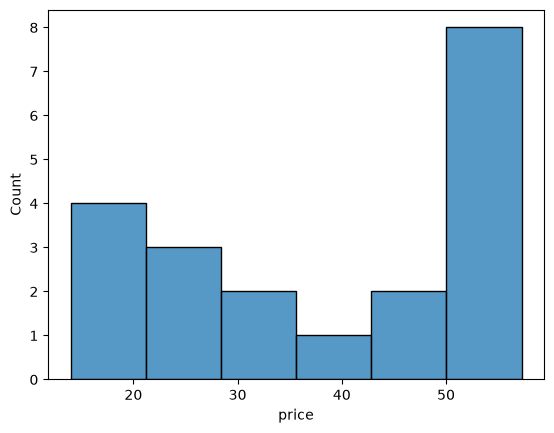

In [48]:
sns.histplot(
    data=books_scraped_df,
    x="price"
);

Most books have `price => 50`

#### Finding 5

In [62]:
def parse_status_to_available(status: str) -> str:
    if not status:
        return pd.NA
    return re.search(r"[0-9]+", status).group(0)

In [63]:
books_scraped_df["status"] = books_scraped_df["status"].apply(parse_status_to_available).astype("int64")

In [70]:
books_scraped_df = books_scraped_df.rename(columns={"status": "available"})

In [71]:
books_scraped_df

,title,price,available,UPC
0,A Light in the Attic,51.77,22,a897fe39b1053632
1,Tipping the Velvet,53.74,20,90fa61229261140a
2,Soumission,50.10,20,6957f44c3847a760
3,Sharp Objects,47.82,20,e00eb4fd7b871a48
4,Sapiens: A Brief History of Humankind,54.23,20,4165285e1663650f
5,The Requiem Red,22.65,19,f77dbf2323deb740
6,The Dirty Little Secrets of Getting Your Dream...,33.34,19,2597b5a345f45e1b
7,The Coming Woman: A Novel Based on the Life of...,17.93,19,e72a5dfc7e9267b2
8,The Boys in the Boat: Nine Americans and Their...,22.60,19,e10e1e165dc8be4a
9,The Black Maria,52.15,19,1dfe412b8ac00530


#### Finding 5

In [74]:
books_scraped_df["available"].sum()

np.int64(387)

Total of `387` books are avalable.

### Comparison API vs Web Scraping

Retrieving data from api is easier, as it is provides data in ready to read format using either dict passed to DataFrame constructor or read_json method. But the hard part is dealing with object data types (arrays of values), that need to be normalized either by casting them into special character deilmeted strings, or creating several DataFramses objects.

Using webscraping is much harder as it requires dealing with DOM of the page, in order to find necessary class or other identifying infromation to seperate needed data from the html. Also, in modern web applications static pages are rare, making usage of simple requests like libraries impossible. To scrap JS generated pages, other libraries are needed, that are waiting for page to be generated completely.